# California Housing: OLS vs Ridge vs Lasso Regression
Predicting `median_house_value` with engineered interaction features, median imputation, multicollinearity diagnostics (correlation matrix and VIF), and a comparison of OLS, Ridge (L2) and Lasso (L1) tuned with `GridSearchCV`. Models are compared on RMSE, MAE and R².

**Workflow:** load → missing values → correlation analysis → train/test split → imputation + feature engineering → VIF → scaling and encoding → OLS baseline → Ridge/Lasso grid search → evaluation → predicted vs actual and residual diagnostics.

## 1. Imports and configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import make_column_selector
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy import stats

RANDOM_STATE = 42
TARGET = "median_house_value"
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.4f}".format

## 2. Load the dataset

In [2]:
df = pd.read_csv("housing.csv")
print(f"Shape: {df.shape}")
df.head()

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.2300,37.8800,41.0000,880.0000,129.0000,322.0000,126.0000,8.3252,"452,600.0000",NEAR BAY
1,-122.2200,37.8600,21.0000,"7,099.0000","1,106.0000","2,401.0000","1,138.0000",8.3014,"358,500.0000",NEAR BAY
2,-122.2400,37.8500,52.0000,"1,467.0000",190.0000,496.0000,177.0000,7.2574,"352,100.0000",NEAR BAY
3,-122.2500,37.8500,52.0000,"1,274.0000",235.0000,558.0000,219.0000,5.6431,"341,300.0000",NEAR BAY
4,-122.2500,37.8500,52.0000,"1,627.0000",280.0000,565.0000,259.0000,3.8462,"342,200.0000",NEAR BAY


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,"20,640.0000",-119.5697,2.0035,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100
latitude,"20,640.0000",35.6319,2.1360,32.5400,33.9300,34.2600,37.7100,41.9500
housing_median_age,"20,640.0000",28.6395,12.5856,1.0000,18.0000,29.0000,37.0000,52.0000
total_rooms,"20,640.0000","2,635.7631","2,181.6153",2.0000,"1,447.7500","2,127.0000","3,148.0000","39,320.0000"
total_bedrooms,"20,433.0000",537.8706,421.3851,1.0000,296.0000,435.0000,647.0000,"6,445.0000"
population,"20,640.0000","1,425.4767","1,132.4621",3.0000,787.0000,"1,166.0000","1,725.0000","35,682.0000"
households,"20,640.0000",499.5397,382.3298,1.0000,280.0000,409.0000,605.0000,"6,082.0000"
median_income,"20,640.0000",3.8707,1.8998,0.4999,2.5634,3.5348,4.7432,15.0001
median_house_value,"20,640.0000","206,855.8169","115,395.6159","14,999.0000","119,600.0000","179,700.0000","264,725.0000","500,001.0000"


## 3. Missing values and target inspection

In [5]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(3)
pd.DataFrame({"missing": missing, "percent": missing_pct})[missing > 0]

,missing,percent
total_bedrooms,207,1.0030


Rows at the maximum target value (500,001): 965 (4.68%)


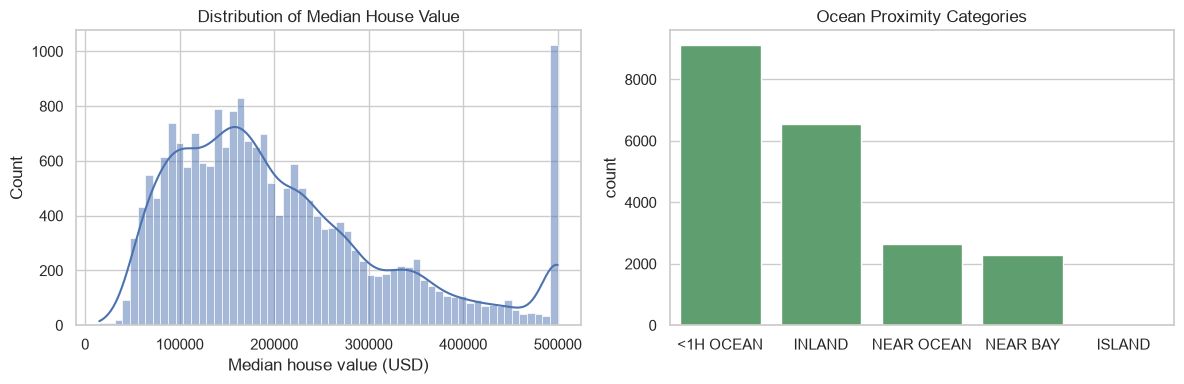

In [6]:
capped = (df[TARGET] == df[TARGET].max()).sum()
print(f"Rows at the maximum target value ({df[TARGET].max():,.0f}): {capped} ({capped / len(df):.2%})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=60, kde=True, color="#4C72B0", ax=axes[0])
axes[0].set_title("Distribution of Median House Value")
axes[0].set_xlabel("Median house value (USD)")
sns.countplot(data=df, x="ocean_proximity", order=df["ocean_proximity"].value_counts().index,
              color="#55A868", ax=axes[1])
axes[1].set_title("Ocean Proximity Categories")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

The target is right-skewed and censored at roughly 500,000, so a cluster of districts share the same capped value. Linear models cannot fit that ceiling well, which limits achievable R² and shows up later as a pattern in the residuals. Only `total_bedrooms` has missing values (about 1%), and `ISLAND` has just five rows.

## 4. Correlation analysis (raw features)

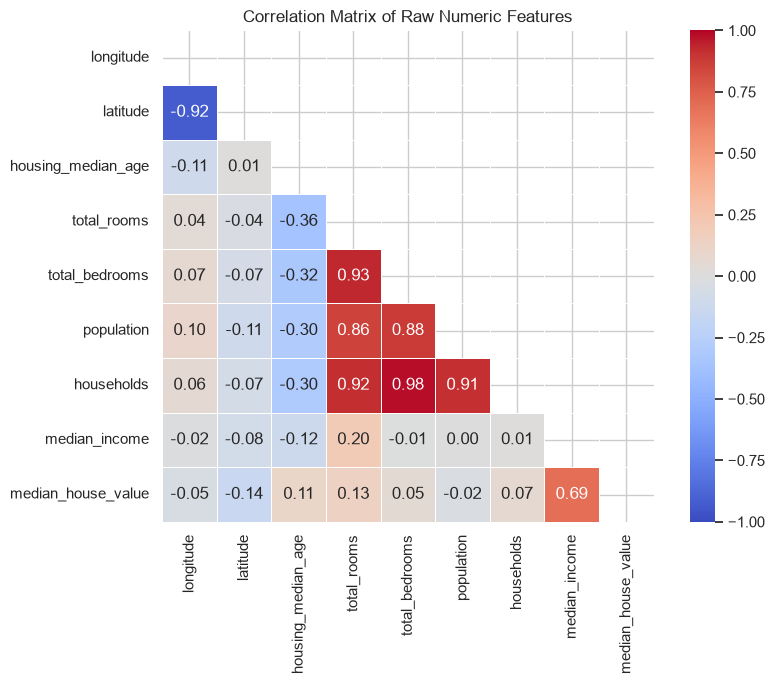

In [7]:
numeric_raw = df.drop(columns=["ocean_proximity"])
corr_raw = numeric_raw.corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_raw, dtype=bool))
sns.heatmap(corr_raw, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation Matrix of Raw Numeric Features")
plt.tight_layout()
plt.show()

In [8]:
corr_raw[TARGET].drop(TARGET).sort_values(ascending=False).to_frame("correlation with target")

,correlation with target
median_income,0.6881
total_rooms,0.1342
housing_median_age,0.1056
households,0.0658
total_bedrooms,0.0497
population,-0.0246
longitude,-0.0460
latitude,-0.1442


`total_rooms`, `total_bedrooms`, `population` and `households` are almost perfectly correlated with one another (0.86 to 0.98) because all four scale with the size of a district. `latitude` and `longitude` are also strongly negatively correlated. This is the multicollinearity that will destabilize OLS coefficients. `median_income` is the strongest single predictor of house value.

## 5. Train/test split
The split happens before any imputation, scaling or feature engineering so that no statistic is learned from the test data.

In [9]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (16512, 9) | Test: (4128, 9)


## 6. Imputation and interaction feature engineering

In [10]:
raw_numeric_cols = [c for c in X.columns if c != "ocean_proximity"]
categorical_features = ["ocean_proximity"]

imputer = ColumnTransformer(
    [("median_impute", SimpleImputer(strategy="median"), raw_numeric_cols)],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")


class FeatureEngineer(BaseEstimator, TransformerMixin):
    RATIOS = {
        "rooms_per_household": ("total_rooms", "households"),
        "bedrooms_per_room": ("total_bedrooms", "total_rooms"),
        "population_per_household": ("population", "households"),
    }
    CENTERED = ["median_income", "latitude", "longitude", "housing_median_age"]

    def __init__(self, drop_cols=()):
        self.drop_cols = drop_cols

    def _ratios(self, data):
        return pd.DataFrame({name: data[num] / data[den] for name, (num, den) in self.RATIOS.items()}, index=data.index)

    def fit(self, data, y=None):
        ratios = self._ratios(data)
        self.bounds_ = {c: (ratios[c].quantile(0.01), ratios[c].quantile(0.99)) for c in ratios}
        clipped = ratios.clip(lower=pd.Series({c: b[0] for c, b in self.bounds_.items()}),
                              upper=pd.Series({c: b[1] for c, b in self.bounds_.items()}), axis=1)
        self.centers_ = data[self.CENTERED].median()
        self.rooms_center_ = clipped["rooms_per_household"].median()
        return self

    def transform(self, data):
        out = data.copy()
        ratios = self._ratios(data)
        for c in ratios:
            out[c] = ratios[c].clip(*self.bounds_[c])

        income = data["median_income"] - self.centers_["median_income"]
        lat = data["latitude"] - self.centers_["latitude"]
        lon = data["longitude"] - self.centers_["longitude"]
        age = data["housing_median_age"] - self.centers_["housing_median_age"]
        rooms = out["rooms_per_household"] - self.rooms_center_

        out["income_x_rooms_per_hh"] = income * rooms
        out["income_x_age"] = income * age
        out["income_x_lat"] = income * lat
        out["income_x_lon"] = income * lon
        out["lat_x_lon"] = lat * lon
        out["income_sq"] = income ** 2
        return out.drop(columns=list(self.drop_cols))

Three kinds of features are added. Per-household ratios (rooms, bedrooms-to-rooms, population) describe the housing stock rather than district size, and they are clipped at the training 1st and 99th percentiles because a handful of extreme districts (for example, more than 100 rooms per household) otherwise dominate a linear fit. Interaction terms capture effects that a purely additive model misses: income × rooms per household, income × housing age, income × latitude, income × longitude, latitude × longitude, and a squared income term. The interaction inputs are mean-centered first, which keeps the products from being trivially collinear with their parents. Imputation medians, clipping bounds and centers are all learned from the training set only.

In [11]:
fe_full = Pipeline([("impute", imputer), ("engineer", FeatureEngineer())])
X_train_full = fe_full.fit_transform(X_train)

print("Missing values after imputation (train):", int(X_train_full.isnull().sum().sum()))
X_train_full.head()

Missing values after imputation (train): 0


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_x_rooms_per_hh,income_x_age,income_x_lat,income_x_lon,lat_x_lon,income_sq
14196,-117.0300,32.7100,33.0000,"3,126.0000",627.0000,"2,300.0000",623.0000,3.2596,NEAR OCEAN,5.0177,0.2006,3.6918,0.0625,-1.1448,0.4436,-0.4236,-2.2940,0.0819
8267,-118.1600,33.7700,49.0000,"3,382.0000",787.0000,"1,314.0000",756.0000,3.8125,NEAR OCEAN,4.4735,0.2327,1.7381,-0.2033,5.3340,-0.1307,0.0933,-0.1715,0.0711
17445,-120.4800,34.6600,4.0000,"1,897.0000",331.0000,915.0000,336.0000,4.1563,NEAR OCEAN,5.6458,0.1745,2.7232,0.2503,-15.2625,0.2442,-1.2027,-0.7880,0.3727
14265,-117.1100,32.6900,36.0000,"1,421.0000",367.0000,"1,418.0000",355.0000,1.9425,NEAR OCEAN,4.0028,0.2583,3.9944,1.9770,-11.2231,2.5172,-2.2446,-2.1980,2.5706
2271,-119.8000,36.7800,43.0000,"2,382.0000",431.0000,874.0000,380.0000,3.5542,INLAND,6.2684,0.1809,2.3000,0.0087,0.1176,0.0212,-0.0108,-3.2508,0.0001


## 7. Multicollinearity handling: correlation and VIF

In [12]:
def compute_vif(frame):
    corr = np.corrcoef(frame.values, rowvar=False)
    return pd.Series(np.diag(np.linalg.inv(corr)), index=frame.columns)


numeric_full = X_train_full.select_dtypes("number")
raw_train = X_train[raw_numeric_cols].fillna(X_train[raw_numeric_cols].median())

vif_table = pd.concat(
    {"VIF (raw)": compute_vif(raw_train), "VIF (engineered, full)": compute_vif(numeric_full)}, axis=1
).sort_values("VIF (engineered, full)", ascending=False)
vif_table

,VIF (raw),"VIF (engineered, full)"
households,35.8246,70.6337
total_bedrooms,36.3071,67.1571
total_rooms,12.8218,22.1338
income_x_lat,NaN,18.5769
income_x_lon,NaN,17.3120
population,6.3454,13.3603
latitude,8.7983,12.3841
longitude,8.6818,11.1606
rooms_per_household,NaN,6.6089
bedrooms_per_room,NaN,6.3411


`households` and `total_bedrooms` have the highest VIFs. Total bedrooms is the more redundant of the two: it is almost fully determined by `total_rooms` together with `bedrooms_per_room`, and it also moves with `households` and `population`. It is removed. The remaining collinearity (latitude and longitude with their products, the other district-size columns) is not dropped, because those terms carry signal; it is left to the L2 and L1 penalties.

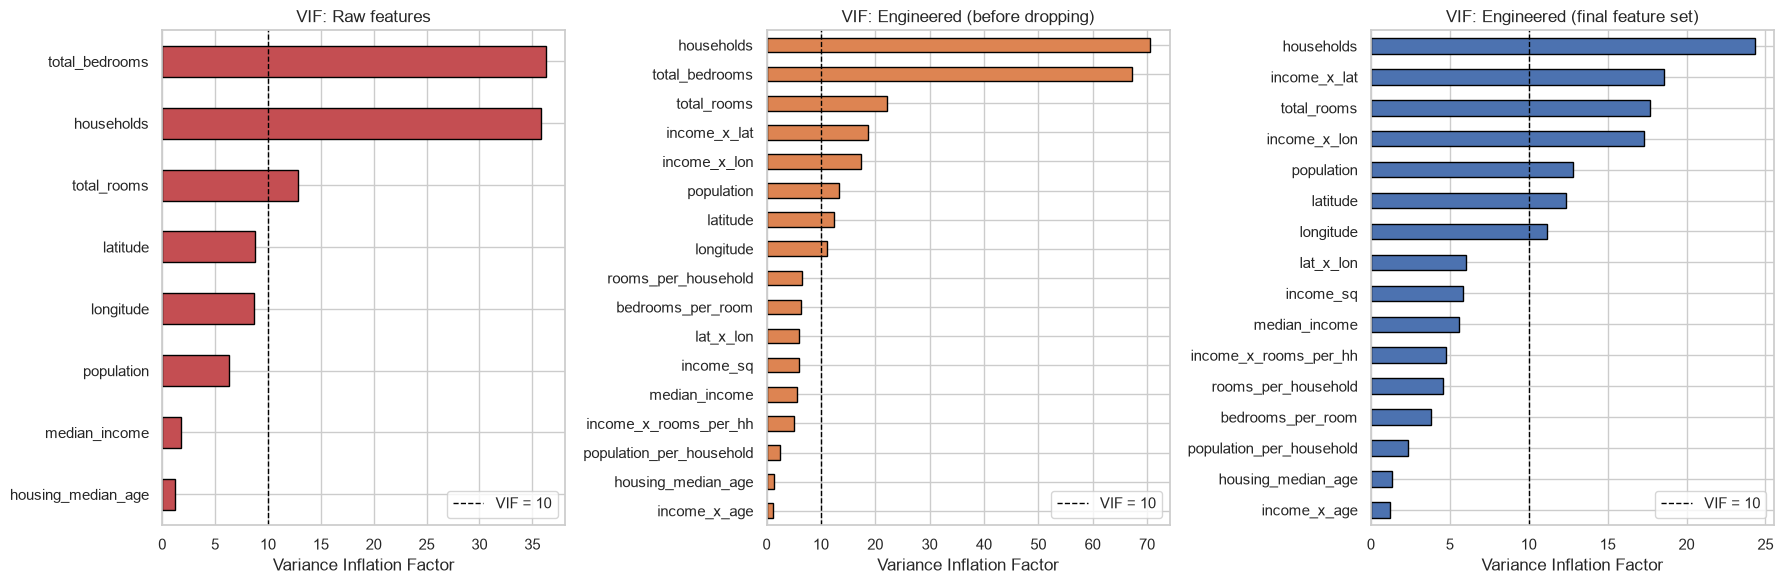

In [13]:
DROP_COLS = ("total_bedrooms",)

feature_prep = Pipeline([("impute", imputer), ("engineer", FeatureEngineer(drop_cols=DROP_COLS))])
X_train_fe = feature_prep.fit_transform(X_train)
numeric_final = X_train_fe.select_dtypes("number")

vif_final = compute_vif(numeric_final)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, series, title, color in [
    (axes[0], compute_vif(raw_train), "Raw features", "#C44E52"),
    (axes[1], compute_vif(numeric_full), "Engineered (before dropping)", "#DD8452"),
    (axes[2], vif_final, "Engineered (final feature set)", "#4C72B0"),
]:
    series.sort_values().plot(kind="barh", ax=ax, color=color, edgecolor="black")
    ax.axvline(10, color="black", linestyle="--", linewidth=1, label="VIF = 10")
    ax.set_title(f"VIF: {title}")
    ax.set_xlabel("Variance Inflation Factor")
    ax.legend()
plt.tight_layout()
plt.show()

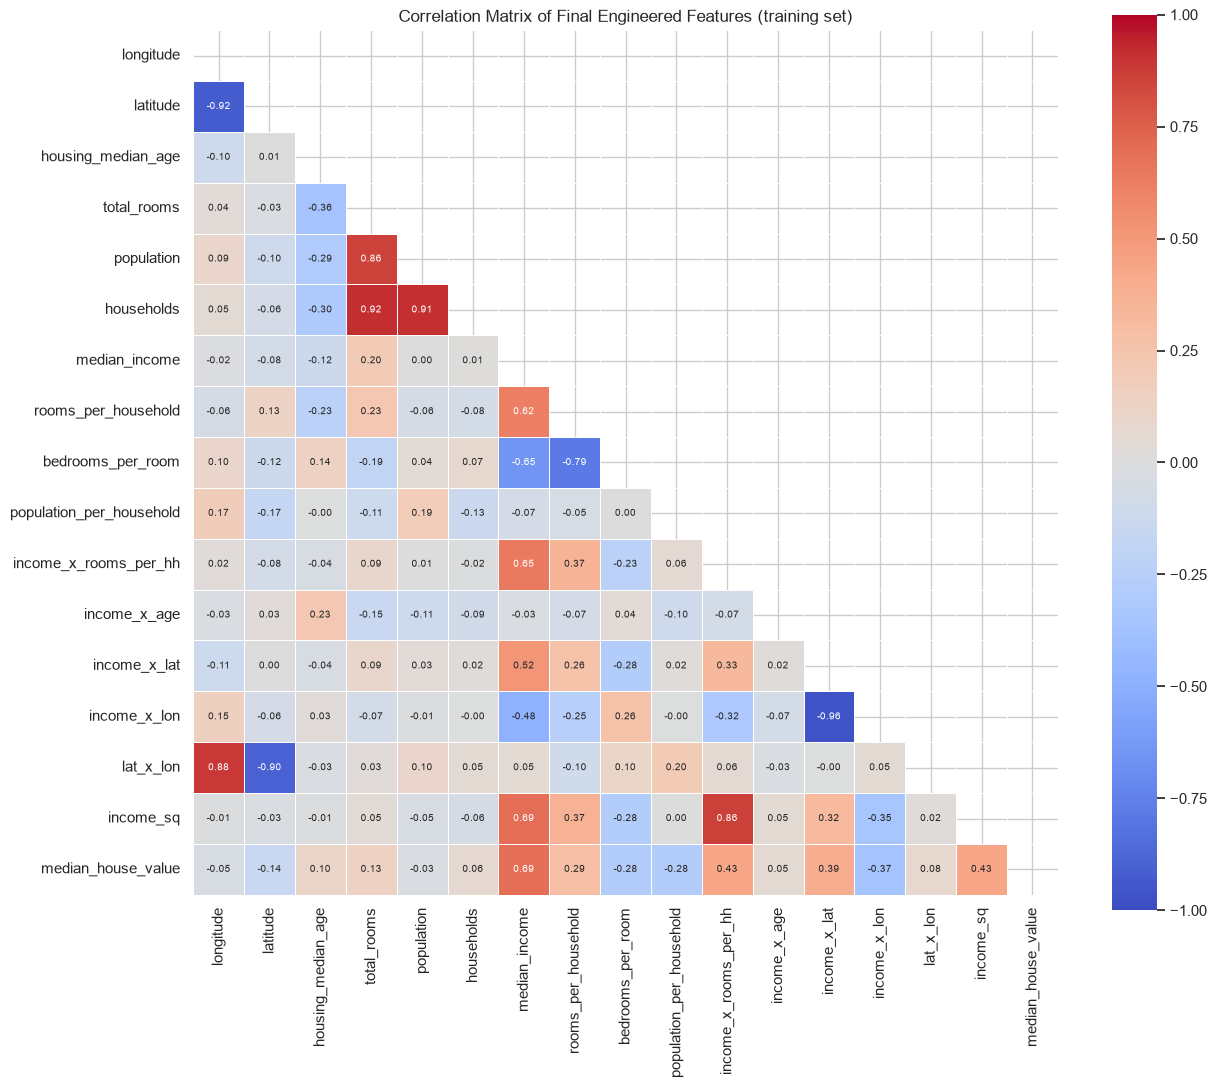

In [14]:
train_corr_fe = numeric_final.assign(**{TARGET: y_train.values}).corr()

fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(train_corr_fe, dtype=bool))
sns.heatmap(train_corr_fe, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation Matrix of Final Engineered Features (training set)")
plt.tight_layout()
plt.show()

## 8. Scaling and categorical encoding

In [15]:
encode_scale = ColumnTransformer(
    [
        ("scale", StandardScaler(), make_column_selector(dtype_include="number")),
        ("encode", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_features),
    ]
)


def build_pipeline(estimator):
    return Pipeline([
        ("impute", imputer),
        ("engineer", FeatureEngineer(drop_cols=DROP_COLS)),
        ("encode_scale", encode_scale),
        ("model", estimator),
    ])

## 9. Evaluation helpers

In [16]:
def evaluate(model, X_tr, y_tr, X_te, y_te):
    pred_tr, pred_te = model.predict(X_tr), model.predict(X_te)
    return {
        "RMSE (train)": np.sqrt(mean_squared_error(y_tr, pred_tr)),
        "RMSE (test)": np.sqrt(mean_squared_error(y_te, pred_te)),
        "MAE (train)": mean_absolute_error(y_tr, pred_tr),
        "MAE (test)": mean_absolute_error(y_te, pred_te),
        "R² (train)": r2_score(y_tr, pred_tr),
        "R² (test)": r2_score(y_te, pred_te),
    }

## 10. Baseline and OLS

In [17]:
raw_baseline = Pipeline([
    ("preprocess", ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), raw_numeric_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_features),
    ])),
    ("model", LinearRegression()),
]).fit(X_train, y_train)

ols = build_pipeline(LinearRegression()).fit(X_train, y_train)

pd.DataFrame({
    "OLS (raw features)": evaluate(raw_baseline, X_train, y_train, X_test, y_test),
    "OLS (engineered features)": evaluate(ols, X_train, y_train, X_test, y_test),
}).T

,RMSE (train),RMSE (test),MAE (train),MAE (test),R² (train),R² (test)
OLS (raw features),"68,433.9374","70,059.1933","49,594.8421","50,670.4892",0.6497,0.6254
OLS (engineered features),"63,662.7499","66,659.3803","46,162.1351","48,100.1452",0.6968,0.6609


The first row is a plain OLS on the raw columns and serves as a baseline, so the gain from feature engineering can be measured directly.

## 11. Ridge and Lasso with GridSearchCV

In [18]:
alphas = np.logspace(-1, 4, 16)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_search = GridSearchCV(
    build_pipeline(Ridge(random_state=RANDOM_STATE)),
    param_grid={"model__alpha": alphas},
    scoring="neg_root_mean_squared_error",
    cv=cv, n_jobs=-1, return_train_score=True,
).fit(X_train, y_train)

lasso_search = GridSearchCV(
    build_pipeline(Lasso(max_iter=20000, tol=1e-3, random_state=RANDOM_STATE)),
    param_grid={"model__alpha": alphas},
    scoring="neg_root_mean_squared_error",
    cv=cv, n_jobs=-1, return_train_score=True,
).fit(X_train, y_train)

print(f"Ridge  best alpha: {ridge_search.best_params_['model__alpha']:.4f} | CV RMSE: {-ridge_search.best_score_:,.2f}")
print(f"Lasso  best alpha: {lasso_search.best_params_['model__alpha']:.4f} | CV RMSE: {-lasso_search.best_score_:,.2f}")

Ridge  best alpha: 2.1544 | CV RMSE: 63,759.43
Lasso  best alpha: 10.0000 | CV RMSE: 63,765.75


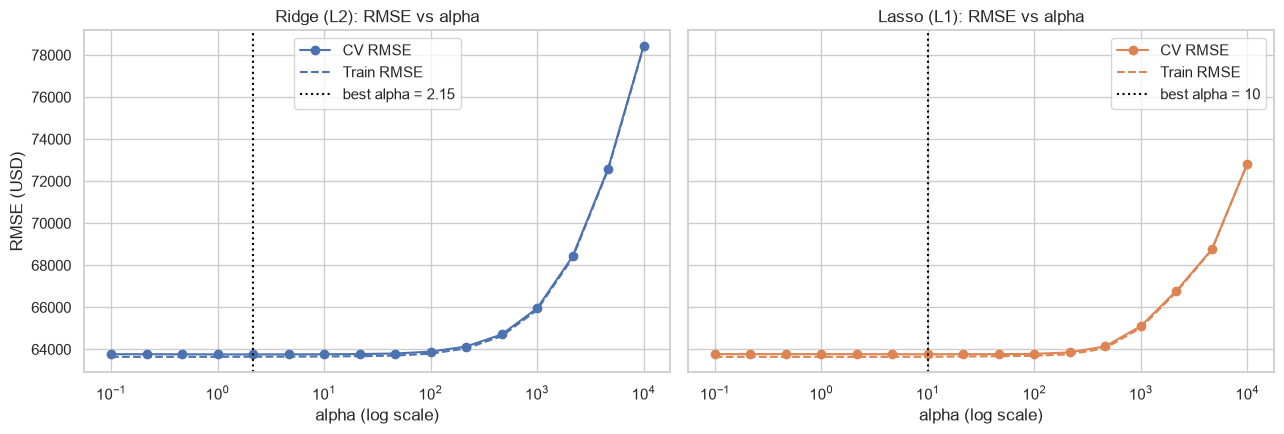

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, search, name, color in [
    (axes[0], ridge_search, "Ridge (L2)", "#4C72B0"),
    (axes[1], lasso_search, "Lasso (L1)", "#DD8452"),
]:
    res = pd.DataFrame(search.cv_results_)
    ax.semilogx(res["param_model__alpha"].astype(float), -res["mean_test_score"], color=color, marker="o", label="CV RMSE")
    ax.semilogx(res["param_model__alpha"].astype(float), -res["mean_train_score"], color=color, linestyle="--", label="Train RMSE")
    best = search.best_params_["model__alpha"]
    ax.axvline(best, color="black", linestyle=":", label=f"best alpha = {best:.3g}")
    ax.set_title(f"{name}: RMSE vs alpha")
    ax.set_xlabel("alpha (log scale)")
    ax.legend()
axes[0].set_ylabel("RMSE (USD)")
plt.tight_layout()
plt.show()

In [20]:
ridge = ridge_search.best_estimator_
lasso = lasso_search.best_estimator_
models = {"OLS": ols, "Ridge (L2)": ridge, "Lasso (L1)": lasso}

## 12. Model comparison

In [21]:
results = pd.DataFrame({name: evaluate(m, X_train, y_train, X_test, y_test) for name, m in models.items()}).T
results

,RMSE (train),RMSE (test),MAE (train),MAE (test),R² (train),R² (test)
OLS,"63,662.7499","66,659.3803","46,162.1351","48,100.1452",0.6968,0.6609
Ridge (L2),"63,665.9829","66,670.7075","46,164.6283","48,111.3269",0.6968,0.6608
Lasso (L1),"63,666.2083","66,672.5500","46,166.0257","48,113.0666",0.6968,0.6608


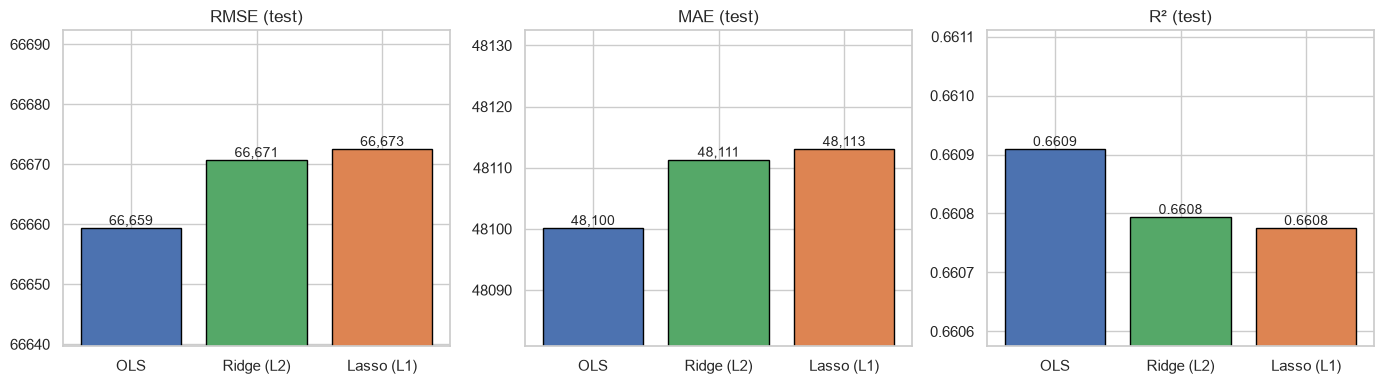

In [22]:
test_metrics = results[["RMSE (test)", "MAE (test)", "R² (test)"]]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = ["#4C72B0", "#55A868", "#DD8452"]
for ax, col in zip(axes, test_metrics.columns):
    ax.bar(test_metrics.index, test_metrics[col], color=colors, edgecolor="black")
    ax.set_title(col)
    lo, hi = test_metrics[col].min(), test_metrics[col].max()
    pad = (hi - lo) * 1.5 if hi > lo else hi * 0.01
    ax.set_ylim(lo - pad, hi + pad)
    for i, v in enumerate(test_metrics[col]):
        ax.text(i, v, f"{v:,.4f}" if "R²" in col else f"{v:,.0f}", ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.show()

## 13. Coefficients and feature selection

In [23]:
feature_names = ols.named_steps["encode_scale"].get_feature_names_out()
feature_names = [n.split("__", 1)[1] for n in feature_names]

coefs = pd.DataFrame({
    "OLS": ols.named_steps["model"].coef_,
    "Ridge (L2)": ridge.named_steps["model"].coef_,
    "Lasso (L1)": lasso.named_steps["model"].coef_,
}, index=feature_names)

coefs.round(2)

,OLS,Ridge (L2),Lasso (L1)
longitude,"-61,682.8500","-61,494.4400","-61,395.7800"
latitude,"-49,540.7300","-49,329.5500","-49,292.2700"
housing_median_age,"13,697.6700","13,708.0500","13,689.9100"
total_rooms,-165.8800,-130.8700,0.0000
population,"-3,311.6700","-3,308.1400","-3,127.1800"
households,"7,665.3300","7,629.0500","7,318.3100"
median_income,"93,643.7000","93,532.8400","93,522.9600"
rooms_per_household,"14,184.1100","14,191.3800","14,106.5000"
bedrooms_per_room,"27,390.9500","27,372.3600","27,352.8100"
population_per_household,"-23,712.3900","-23,726.4000","-23,780.1900"


Coefficients set exactly to zero by Lasso: 1 of 20
Zeroed features: ['total_rooms']


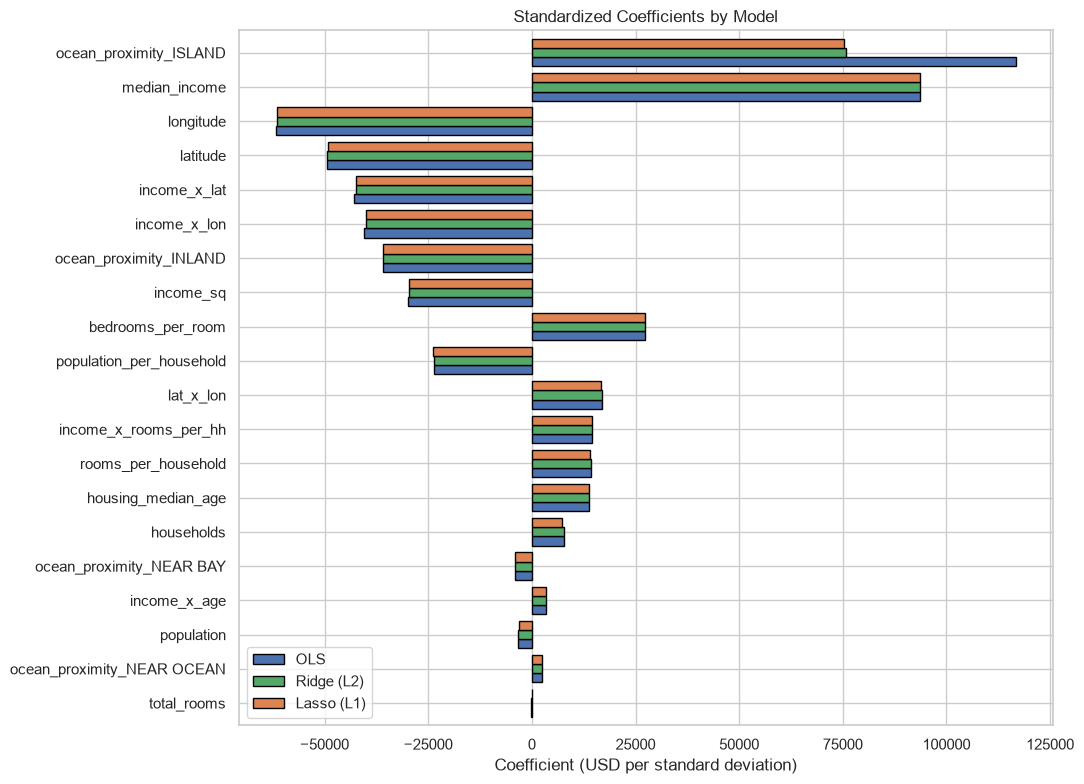

In [24]:
print("Coefficients set exactly to zero by Lasso:", int((coefs["Lasso (L1)"] == 0).sum()), "of", len(coefs))
print("Zeroed features:", list(coefs.index[coefs["Lasso (L1)"] == 0]) or "none")

ordered = coefs.reindex(coefs["OLS"].abs().sort_values().index)
ax = ordered.plot(kind="barh", figsize=(11, 8), width=0.8, edgecolor="black", color=["#4C72B0", "#55A868", "#DD8452"])
ax.set_title("Standardized Coefficients by Model")
ax.set_xlabel("Coefficient (USD per standard deviation)")
plt.tight_layout()
plt.show()

## 14. Predicted vs actual

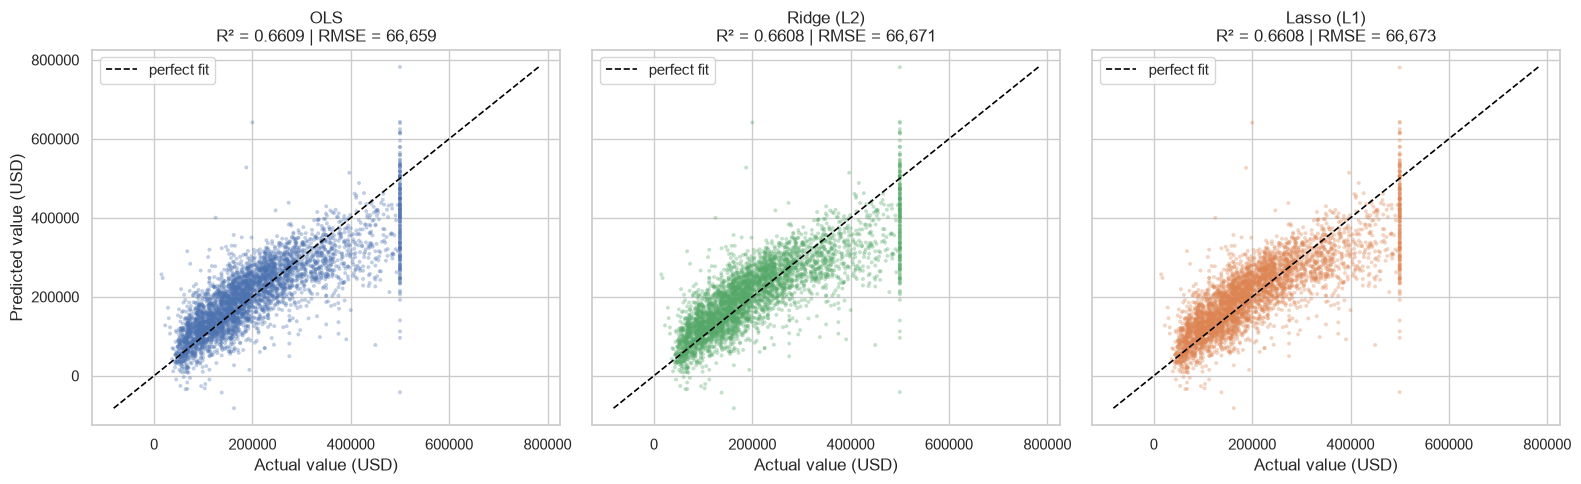

In [25]:
predictions = {name: m.predict(X_test) for name, m in models.items()}
lims = [min(y_test.min(), min(p.min() for p in predictions.values())),
        max(y_test.max(), max(p.max() for p in predictions.values()))]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, (name, pred), color in zip(axes, predictions.items(), colors):
    ax.scatter(y_test, pred, s=8, alpha=0.35, color=color, edgecolor="none")
    ax.plot(lims, lims, color="black", linestyle="--", linewidth=1.2, label="perfect fit")
    ax.set_title(f"{name}\nR² = {r2_score(y_test, pred):.4f} | RMSE = {np.sqrt(mean_squared_error(y_test, pred)):,.0f}")
    ax.set_xlabel("Actual value (USD)")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Predicted value (USD)")
plt.tight_layout()
plt.show()

## 15. Residual analysis

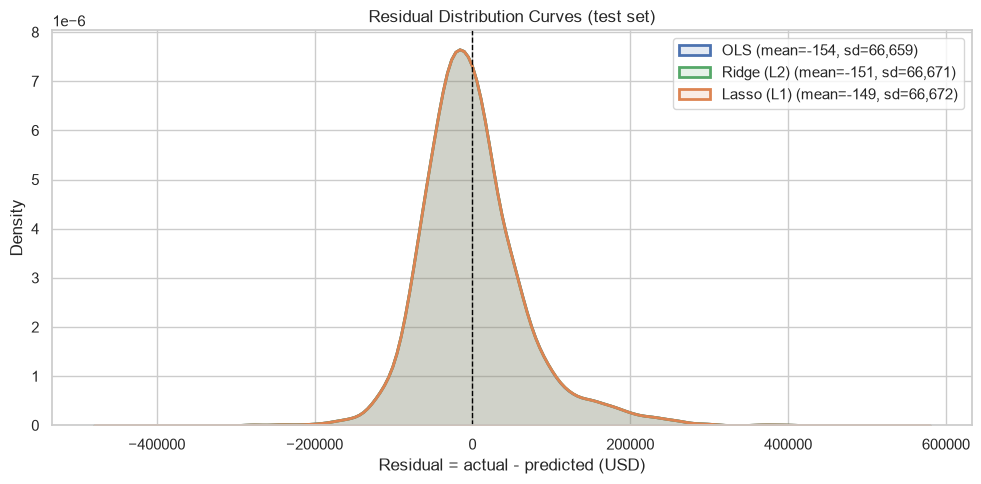

In [26]:
residuals = {name: y_test.values - pred for name, pred in predictions.items()}

fig, ax = plt.subplots(figsize=(10, 5))
for (name, res), color in zip(residuals.items(), colors):
    sns.kdeplot(res, ax=ax, label=f"{name} (mean={res.mean():,.0f}, sd={res.std():,.0f})", color=color, linewidth=2, fill=True, alpha=0.15)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_title("Residual Distribution Curves (test set)")
ax.set_xlabel("Residual = actual - predicted (USD)")
ax.legend()
plt.tight_layout()
plt.show()

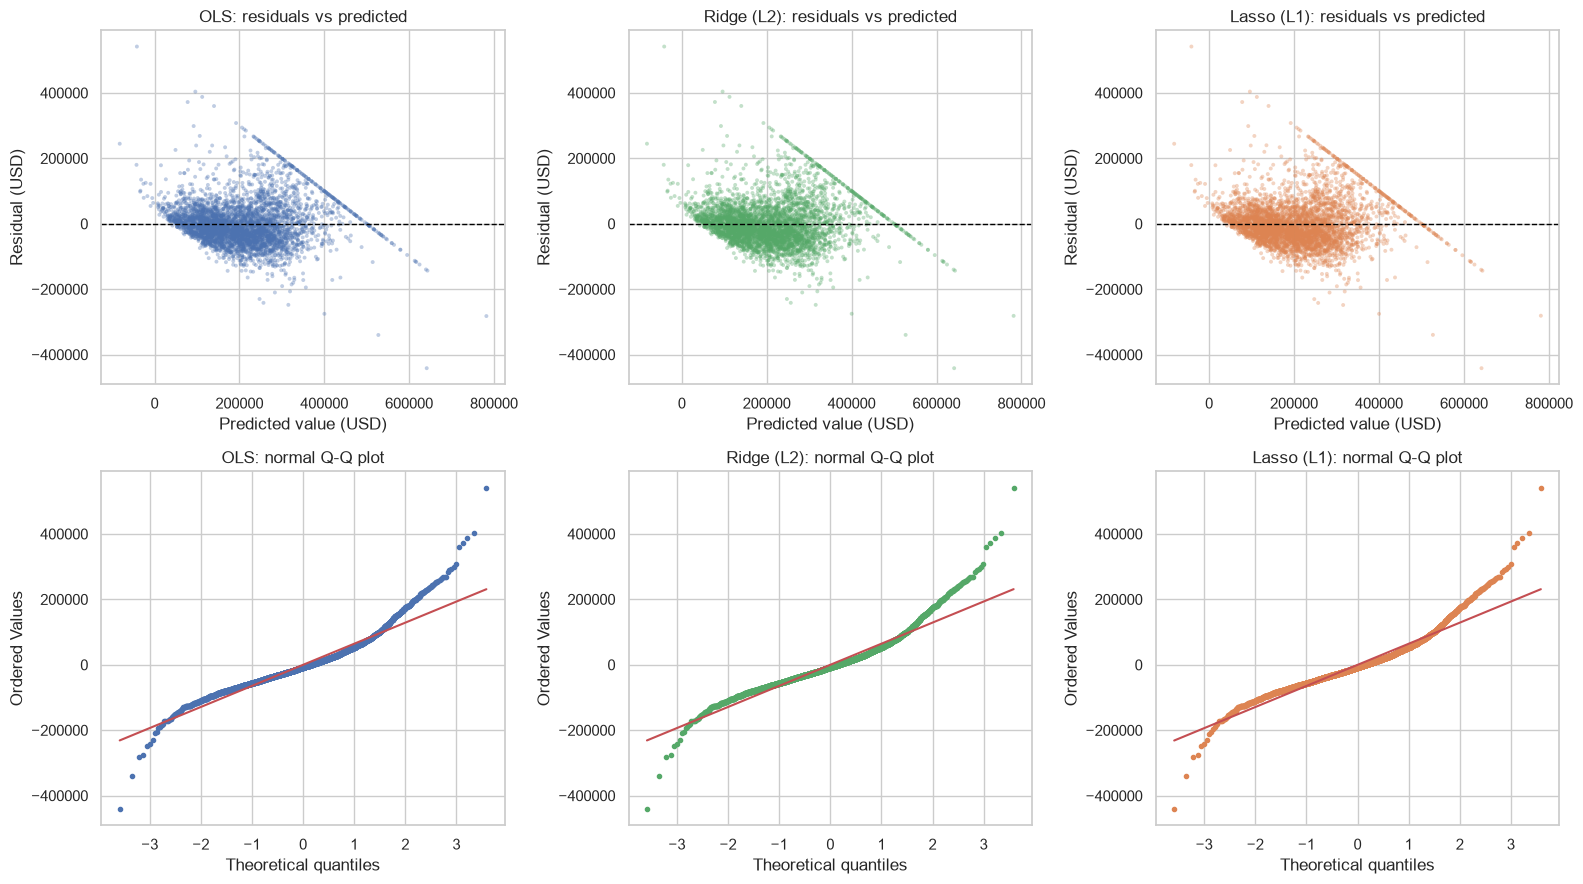

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for col, ((name, res), pred, color) in enumerate(zip(residuals.items(), predictions.values(), colors)):
    axes[0, col].scatter(pred, res, s=8, alpha=0.35, color=color, edgecolor="none")
    axes[0, col].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[0, col].set_title(f"{name}: residuals vs predicted")
    axes[0, col].set_xlabel("Predicted value (USD)")
    axes[0, col].set_ylabel("Residual (USD)")

    stats.probplot(res, dist="norm", plot=axes[1, col])
    axes[1, col].get_lines()[0].set_markerfacecolor(color)
    axes[1, col].get_lines()[0].set_markeredgecolor(color)
    axes[1, col].get_lines()[0].set_markersize(3)
    axes[1, col].set_title(f"{name}: normal Q-Q plot")
plt.tight_layout()
plt.show()

In [28]:
pd.DataFrame({
    name: {
        "mean": res.mean(), "std": res.std(), "skewness": stats.skew(res),
        "excess kurtosis": stats.kurtosis(res),
        "share within ±50k": (np.abs(res) <= 50000).mean(),
    } for name, res in residuals.items()
}).T

,mean,std,skewness,excess kurtosis,share within ±50k
OLS,-153.6313,"66,659.2032",0.9987,4.3986,0.6366
Ridge (L2),-151.2566,"66,670.5360",0.9988,4.3903,0.6366
Lasso (L1),-148.7229,"66,672.3841",0.9997,4.3885,0.6361


## 16. Summary

In [29]:
best_model = results["RMSE (test)"].idxmin()
print(f"Lowest test RMSE: {best_model} ({results.loc[best_model, 'RMSE (test)']:,.2f})")
print(f"Ridge alpha: {ridge_search.best_params_['model__alpha']:.4f} | Lasso alpha: {lasso_search.best_params_['model__alpha']:.4f}")
results[["RMSE (test)", "MAE (test)", "R² (test)"]]

Lowest test RMSE: OLS (66,659.38)
Ridge alpha: 2.1544 | Lasso alpha: 10.0000


,RMSE (test),MAE (test),R² (test)
OLS,"66,659.3803","48,100.1452",0.6609
Ridge (L2),"66,670.7075","48,111.3269",0.6608
Lasso (L1),"66,672.5500","48,113.0666",0.6608


### Findings

- **Feature engineering gave the largest gain.** OLS on the raw columns reaches a test RMSE of about 70,060 (R² 0.625). With clipped per-household ratios and centered interactions, OLS improves to about 66,660 (R² 0.661) and test MAE falls from roughly 50,700 to 48,100. Before the ratios were clipped at the training percentiles, they actually made the model worse, because a few extreme districts dominated the fit.
- **Ridge and Lasso do not beat OLS here.** The three models are nearly identical on every metric (test RMSE 66,659 for OLS, 66,671 for Ridge, 66,673 for Lasso). With about 16,500 training rows and 20 features, OLS has little variance to reduce, and the grid search picked small alphas (about 2.15 for Ridge, 10 for Lasso). Regularization mainly stabilizes the coefficients of the collinear columns instead of improving accuracy.
- **Lasso performs only light selection.** At its best alpha it removes one of the 20 coefficients (`total_rooms`), which is the near-redundant size column. Stronger alphas would remove more features but raise the CV error.
- **Remaining error is structural.** The residuals have a mean near zero but are right-skewed (skewness about 1.0, excess kurtosis about 4.4). In the residual-vs-predicted plot, the diagonal streak of points is the capped districts: their actual value is fixed at 500,001, so the residual shrinks as the prediction rises. A few predictions are also negative, which a linear model cannot prevent. About 4.7% of districts are capped, and nonlinear geography is out of reach for a linear model. Tree-based models or explicit spatial features would be the natural next step.
- **Reading the metrics.** RMSE penalizes the large errors on expensive districts more heavily than MAE, which is why RMSE (about 66,700) sits well above MAE (about 48,100).